# RoadSafe Chicago | Partie 03 : Nettoyage et qualité des données

## Rappel du projet

**RoadSafe Chicago** étudie l'accidentologie routière à Chicago à partir des données ouvertes de la ville.

**Problématique** : *Comment évoluent la fréquence et la gravité des accidents routiers à Chicago, et quels facteurs sont associés à leur gravité ?*

La partie 02 a permis de comprendre la structure des **112 056 accidents de 2024** et de repérer plusieurs problèmes de qualité : valeurs « UNKNOWN », coordonnées à (0, 0), limites de vitesse à 0 mph, blessures non renseignées.

---

## Objectif de cette partie

**Rendre les données fiables et exploitables**, sans perdre d'information ni modifier la source.

Le principe retenu : **signaler plutôt que supprimer**. Les problèmes sont identifiés par des colonnes de qualité (`geo_valid`, `speed_valid`…), afin que chaque analyse puisse filtrer selon ses besoins. Le fichier brut reste intact.

## Contenu de cette partie

1. **Typage** : conversion des dates, des nombres et des indicateurs Y/N, initialement stockés en texte.
2. **Contrôle de la clé** : vérification finale de l'unicité de `crash_record_id`.
3. **Valeurs inconnues** : harmonisation des modalités « UNKNOWN », « NOT REPORTED »… en une seule catégorie.
4. **Valeurs aberrantes** : coordonnées hors de Chicago, limites de vitesse impossibles, délais de signalement incohérents.
5. **Variables dérivées** : indicateurs de gravité (accident avec blessés, mortel, grave), week-end, tranches horaires, classes de vitesse.
6. **Rapport qualité et sauvegarde** : synthèse des corrections et écriture du fichier `data/processed/crashes_2024.parquet`.

## Résultat attendu

- Un jeu de données **typé, harmonisé et documenté**, prêt pour l'analyse exploratoire.
- Un **rapport qualité** qui chiffre chaque problème et la règle appliquée.
- Des **règles de correction traçables**, rejouables sur les autres années (2018-2025).

# Librairies

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

## Importation des données

In [2]:
raw = pd.read_parquet("../data/raw/crashes_2024.parquet")
df = raw.copy()  # on travaille sur une copie, le raw reste intact
print(df.shape)

(112056, 49)


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112056 entries, 0 to 112055
Data columns (total 49 columns):
 #   Column                         Non-Null Count   Dtype 
---  ------                         --------------   ----- 
 0   crash_record_id                112056 non-null  str   
 1   crash_date                     112056 non-null  str   
 2   posted_speed_limit             112056 non-null  str   
 3   traffic_control_device         112056 non-null  str   
 4   device_condition               112056 non-null  str   
 5   weather_condition              112056 non-null  str   
 6   lighting_condition             112056 non-null  str   
 7   first_crash_type               112056 non-null  str   
 8   trafficway_type                112056 non-null  str   
 9   alignment                      112056 non-null  str   
 10  roadway_surface_cond           112056 non-null  str   
 11  road_defect                    112056 non-null  str   
 12  report_type                    106985 non-null  str   


In [4]:
df.head()

,crash_record_id,crash_date,posted_speed_limit,traffic_control_device,device_condition,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,...,location,intersection_related_i,crash_date_est_i,photos_taken_i,statements_taken_i,work_zone_i,work_zone_type,workers_present_i,dooring_i,lane_cnt
0,5082d6e9f9c5c96660e7ec7fd416549e50d3130af3fc5c...,2024-06-27T13:45:00.000,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,PARKING LOT,STRAIGHT AND LEVEL,...,"{'type': 'Point', 'coordinates': ['-87.683127'...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,fd34aa4f12f00106b32134531fc6e805590dbe89fef502...,2024-06-22T18:07:00.000,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,PARKED MOTOR VEHICLE,NOT DIVIDED,STRAIGHT AND LEVEL,...,"{'type': 'Point', 'coordinates': ['-87.646149'...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,f0a652bf48a8c08c8a26cc981e39ed757cd41f8a771761...,2024-06-23T08:41:00.000,10,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,REAR TO REAR,PARKING LOT,STRAIGHT AND LEVEL,...,"{'type': 'Point', 'coordinates': ['-87.652629'...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,973cda531480f4006c44691e5cc8931b9fd9d719a21264...,2024-06-19T07:35:00.000,30,NO CONTROLS,NO CONTROLS,CLEAR,DAYLIGHT,TURNING,T-INTERSECTION,STRAIGHT AND LEVEL,...,"{'type': 'Point', 'coordinates': ['-87.74469',...",Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,e66fd58b2afc22ec6aa176f149d17467d49f7ae1c83910...,2024-07-07T20:47:00.000,30,NO CONTROLS,NO CONTROLS,CLEAR,"DARKNESS, LIGHTED ROAD",PARKED MOTOR VEHICLE,OTHER,STRAIGHT AND LEVEL,...,"{'type': 'Point', 'coordinates': ['-87.72663',...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Typage

In [5]:
# Dates
for col in ["crash_date", "date_police_notified"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

In [6]:

# Entiers (Int64 = entier qui accepte les NA)
int_cols = ["posted_speed_limit", "num_units", "crash_hour", "crash_day_of_week",
            "crash_month", "lane_cnt"] + [c for c in df.columns if c.startswith("injuries_")]
for col in int_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

In [7]:
# Coordonnées
for col in ["latitude", "longitude"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [8]:
# La colonne location (point GeoJSON) duplique latitude et longitude : on la retire
df = df.drop(columns="location")

In [9]:
# Indicateurs Y/N → booléens (NA conservé si non renseigné)
flag_cols = [c for c in df.columns if c.endswith("_i")]
for col in flag_cols:
    df[col] = df[col].map({"Y": True, "N": False}).astype("boolean")

In [10]:

# Enumération Catégoriques
df.dtypes.value_counts()

str               22
Int64             13
boolean            9
datetime64[us]     2
float64            2
Name: count, dtype: int64

## Contrôle de la clé du dataset

In [11]:
print("Doublons crash_record_id :", df["crash_record_id"].duplicated().sum())
print("Clés manquantes :", df["crash_record_id"].isna().sum())
print("Dates invalides :", df["crash_date"].isna().sum())

Doublons crash_record_id : 0
Clés manquantes : 0
Dates invalides : 0


## Harmonisation des valeurs inconnues 



Les modalités « UNKNOWN », « NOT REPORTED » ou les vides sont regroupés en une seule catégorie UNKNOWN. On les garde comme une modalité, plutôt que de les mettre en NA : on peut ainsi mesurer leur poids et décider, analyse par analyse, de les exclure ou non.

In [12]:
cat_cols = ["traffic_control_device", "device_condition", "weather_condition",
            "lighting_condition", "first_crash_type", "trafficway_type", "alignment",
            "roadway_surface_cond", "road_defect", "report_type", "crash_type", "damage",
            "prim_contributory_cause", "sec_contributory_cause", "most_severe_injury",
            "work_zone_type", "street_direction"]

inconnues = ["UNKNOWN", "NOT REPORTED", "UNABLE TO DETERMINE", "NOT APPLICABLE"]

avant = {c: df[c].isin(inconnues).sum() + df[c].isna().sum() for c in cat_cols}

for col in cat_cols:
    df[col] = df[col].replace(inconnues, "UNKNOWN").fillna("UNKNOWN").astype("category")

pd.Series(avant, name="nb_unknown").sort_values(ascending=False)

work_zone_type             111781
sec_contributory_cause      86842
prim_contributory_cause     51766
road_defect                 29744
roadway_surface_cond        14692
device_condition            11787
weather_condition            8826
traffic_control_device       7128
lighting_condition           7093
report_type                  5071
trafficway_type              1605
most_severe_injury            251
first_crash_type                0
alignment                       0
crash_type                      0
damage                          0
street_direction                0
Name: nb_unknown, dtype: int64

« UNABLE TO DETERMINE » apparaît surtout dans les causes déclarées : la police n'a pas pu établir la cause. Le regrouper avec UNKNOWN reste cohérent pour l'analyse, et ce choix est signalé dans le rapport qualité.

**Analyse.** Le volume d'inconnues n'a pas le même sens selon la colonne. `work_zone_type` est inconnu pour la quasi totalité des accidents simplement parce que la plupart ne surviennent pas en zone de travaux : ce n'est pas un défaut de qualité. En revanche, 46 % de causes principales, 77 % de causes secondaires et 27 % de défauts de chaussée inconnus limitent sérieusement l'usage de ces variables. Les variables de contexte utilisées dans l'analyse (météo, luminosité, chaussée) restent sous 15 % d'inconnues.

## Valeurs aberrantes

In [13]:
sns.set_theme(style="whitegrid")

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)  # crée le dossier s'il n'existe pas

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

### 1. Geolocalisation

In [14]:
# Coordonnées valides : à l'intérieur d'un rectangle englobant Chicago
df["geo_valid"] = df["latitude"].between(41.6, 42.1) & df["longitude"].between(-88.0, -87.5)
df.loc[~df["geo_valid"], ["latitude", "longitude"]] = np.nan  # (0, 0) et points hors zone mis à NA
print("Coordonnées invalides ou absentes :", (~df["geo_valid"]).sum())

Coordonnées invalides ou absentes : 1196


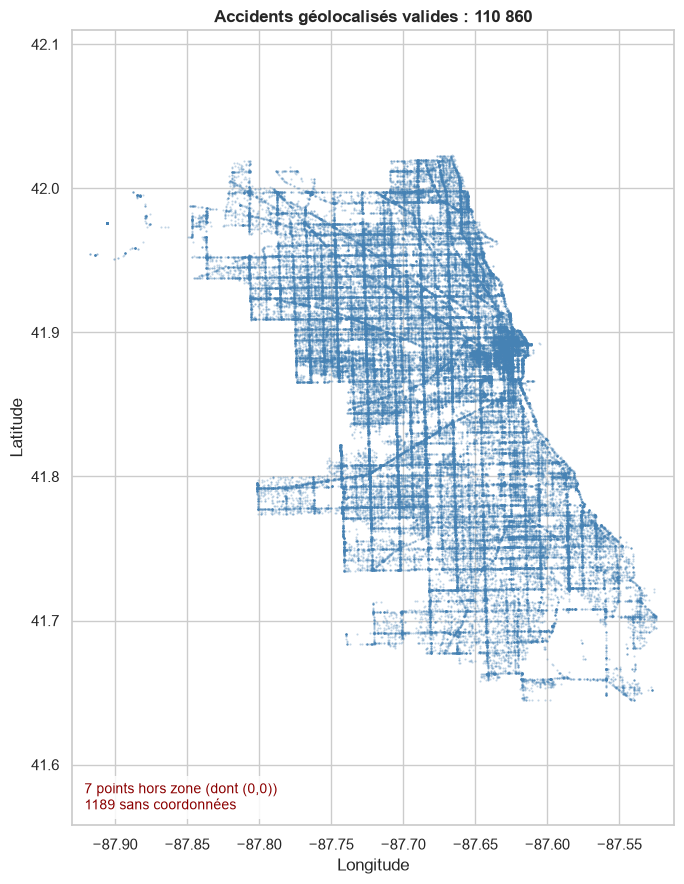

In [15]:
lat_raw = pd.to_numeric(raw["latitude"], errors="coerce")
lon_raw = pd.to_numeric(raw["longitude"], errors="coerce")
hors_zone = (~(lat_raw.between(41.6, 42.1) & lon_raw.between(-88.0, -87.5)) & lat_raw.notna()).sum()

fig, ax = plt.subplots(figsize=(7, 9))
ax.scatter(df["longitude"], df["latitude"], s=0.3, alpha=0.3, color="steelblue")
ax.set_title(f"Accidents géolocalisés valides : {df['geo_valid'].sum():,}".replace(",", " "),
             fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_aspect("equal", adjustable="datalim")
ax.text(0.02, 0.02, f"{hors_zone} points hors zone (dont (0,0))\n{lat_raw.isna().sum()} sans coordonnées",
        transform=ax.transAxes, fontsize=10, color="darkred",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))
save_fig("03_1_geolocalisation")

**Analyse.** 1 196 accidents (1,07 %) sont écartés de la cartographie : 1 189 sans coordonnées et 7 hors de la zone, dont les points à (0, 0). Le nuage de points restant dessine nettement la forme de la ville et son quadrillage de rues : les coordonnées conservées sont cohérentes.

### 2. Limites de vitesse

In [16]:
# Limite réaliste : multiple de 5 entre 5 et 70 mph. Les autres valeurs sont conservées mais signalées
df["speed_valid"] = df["posted_speed_limit"].between(5, 70) & (df["posted_speed_limit"] % 5 == 0)
print("Limites irréalistes :", (~df["speed_valid"]).sum())

Limites irréalistes : 262


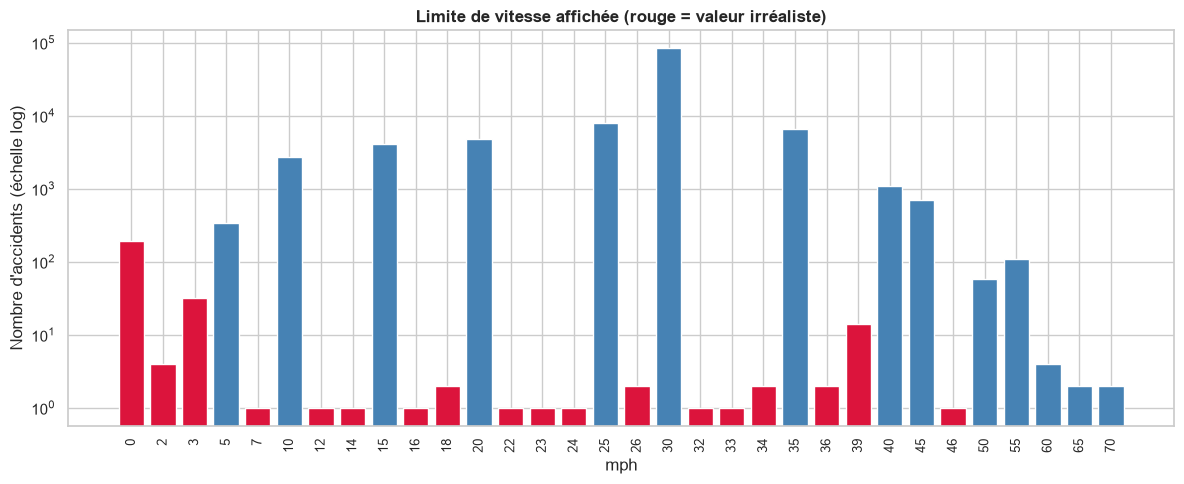

In [17]:
speed_counts = df["posted_speed_limit"].value_counts().sort_index()
colors = ["steelblue" if (5 <= v <= 70 and v % 5 == 0) else "crimson" for v in speed_counts.index]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(speed_counts.index.astype(str), speed_counts.values, color=colors)
ax.set_yscale("log")
ax.set_title("Limite de vitesse affichée (rouge = valeur irréaliste)", fontweight="bold")
ax.set_xlabel("mph"); ax.set_ylabel("Nombre d'accidents (échelle log)")
ax.tick_params(axis="x", rotation=90, labelsize=9)
save_fig("03_2_vitesses")

**Analyse.** La limite de 30 mph, valeur par défaut des rues de Chicago, concerne 74 % des accidents (83 198). 262 valeurs (0,23 %) sont irréalistes : 194 à 0 mph, sans doute un champ non renseigné, et des valeurs comme 3 ou 39 mph qui ressemblent à des erreurs de saisie. Elles sont conservées mais exclues des analyses par vitesse grâce au flag `speed_valid`.

### 3. Délais de signalement

In [18]:
# Délai entre l'accident et le signalement à la police, en heures
df["notification_delay_h"] = ((df["date_police_notified"] - df["crash_date"]).dt.total_seconds() / 3600).round(1)
df["delay_valid"] = df["notification_delay_h"] >= 0  # un signalement ne peut pas précéder l'accident

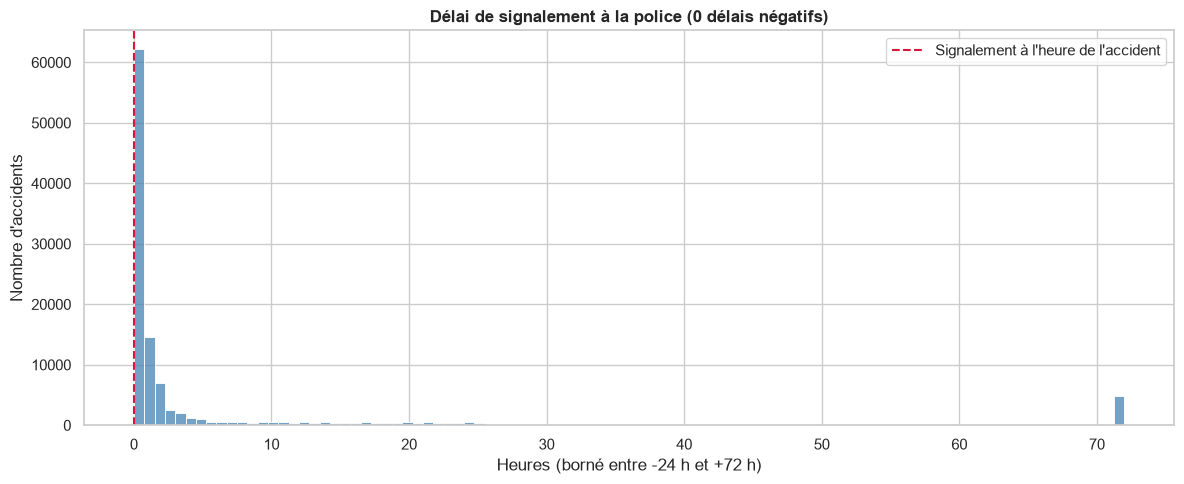

In [19]:
delay = df["notification_delay_h"].dropna()

fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(delay.clip(-24, 72), bins=96, ax=ax, color="steelblue")
ax.axvline(0, color="crimson", linestyle="--", label="Signalement à l'heure de l'accident")
ax.set_title(f"Délai de signalement à la police ({(delay < 0).sum()} délais négatifs)", fontweight="bold")
ax.set_xlabel("Heures (borné entre -24 h et +72 h)"); ax.set_ylabel("Nombre d'accidents")
ax.legend()
save_fig("03_3_delai_signalement")

**Analyse.** Aucun délai négatif : les deux dates sont cohérentes entre elles. Le signalement est très rapide dans la majorité des cas (médiane de 30 minutes, 75 % des accidents signalés en moins de 2,3 heures), mais la distribution a une longue traîne : environ 9 % des accidents sont signalés plus de 24 heures après les faits, vraisemblablement des déclarations différées (accrochages sans blessé, délits de fuite constatés plus tard). Pour ces accidents, l'heure enregistrée est probablement moins précise.

### 4. Synthèse des contrôles

In [20]:
# Blessures renseignées : sans injuries_total, la gravité de l'accident est inconnue
df["injury_info_available"] = df["injuries_total"].notna()

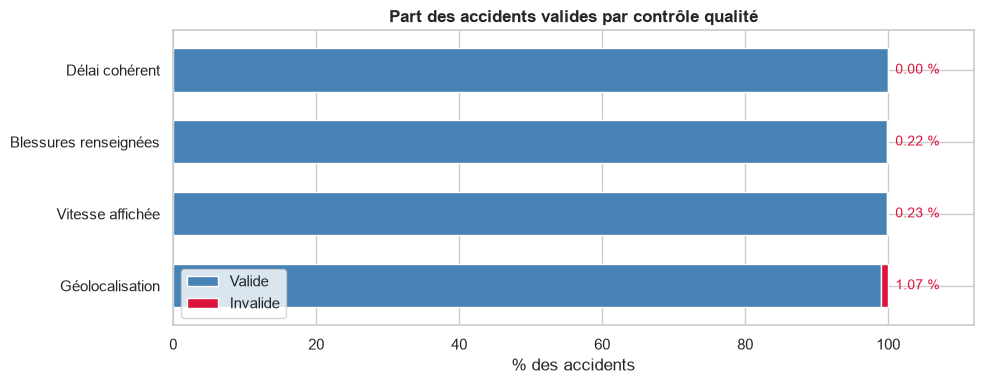

In [21]:
flags = {
    "Géolocalisation": df["geo_valid"],
    "Vitesse affichée": df["speed_valid"],
    "Blessures renseignées": df["injury_info_available"],
    "Délai cohérent": df["delay_valid"],
}
synth = pd.DataFrame({
    "Valide": [f.mean() * 100 for f in flags.values()],
    "Invalide": [(1 - f.mean()) * 100 for f in flags.values()],
}, index=flags.keys())

fig, ax = plt.subplots(figsize=(10, 4))
synth.plot(kind="barh", stacked=True, ax=ax, color=["steelblue", "crimson"], width=0.6)
for i, v in enumerate(synth["Invalide"]):
    ax.text(101, i, f"{v:.2f} %", va="center", fontsize=10, color="crimson")
ax.set_xlim(0, 112)
ax.set_title("Part des accidents valides par contrôle qualité", fontweight="bold")
ax.set_xlabel("% des accidents"); ax.legend(loc="lower left")
save_fig("03_4_synthese_controles")

**Analyse.** Chaque contrôle laisse plus de 98,9 % des accidents valides. La géolocalisation est le contrôle le plus touché (1,07 %), ce qui reste négligeable pour l'analyse spatiale. Les champs structurés sont donc de bonne qualité : la vraie limite du jeu de données se trouve dans les modalités UNKNOWN des variables déclaratives (causes, état de la chaussée).

## Variables derivées utiles pour les Hypothèses et les KPI 

In [22]:
# Gravité (NA si l'information de blessure manque)
df["is_injury"] = (df["injuries_total"] > 0).astype("boolean")
df["is_fatal"] = (df["injuries_fatal"] > 0).astype("boolean")
df["is_severe"] = ((df["injuries_fatal"] > 0) | (df["injuries_incapacitating"] > 0)).astype("boolean")

# Temps (crash_day_of_week : 1 = dimanche, 7 = samedi)
df["is_weekend"] = df["crash_day_of_week"].isin([1, 7])
df["time_slot"] = pd.cut(
    df["crash_hour"], bins=[-1, 5, 9, 15, 19, 23],
    labels=["Nuit (0-5h)", "Matin (6-9h)", "Journée (10-15h)", "Soir (16-19h)", "Nuit (20-23h)"],
    ordered=False,  # deux catégories distinctes pour la nuit, à fusionner au besoin
)
df["season"] = df["crash_month"].map({12: "Hiver", 1: "Hiver", 2: "Hiver",
                                      3: "Printemps", 4: "Printemps", 5: "Printemps",
                                      6: "Été", 7: "Été", 8: "Été",
                                      9: "Automne", 10: "Automne", 11: "Automne"})

# Contexte
df["is_dark"] = df["lighting_condition"].isin(["DARKNESS", "DARKNESS, LIGHTED ROAD"])
df["speed_class"] = pd.cut(
    df["posted_speed_limit"].where(df["speed_valid"]),
    bins=[0, 20, 30, 40, 70], labels=["≤20", "25-30", "35-40", "45+"],
)

df[["is_injury", "is_fatal", "is_severe", "is_weekend", "is_dark"]].mean().mul(100).round(2)

is_injury      16.5
is_fatal        0.1
is_severe      1.56
is_weekend    27.51
is_dark       25.94
dtype: Float64

**Analyse.** 16,5 % des accidents font au moins un blessé, mais seulement 1,56 % sont graves (1 739 accidents) et 0,10 % mortels (111 accidents, 123 décès). Les accidents mortels sont trop peu nombreux pour être étudiés seuls sur une année : `is_severe` sera la variable de gravité principale. Un quart des accidents a lieu de nuit, et 27,5 % le week-end, un peu moins que la part du week-end dans la semaine (2 jours sur 7, soit 28,6 %).

## Rapport qualité et sauvegarde

In [23]:


rapport = pd.DataFrame([
    {"contrôle": "Doublons sur la clé", "nb_lignes": int(df["crash_record_id"].duplicated().sum()), "règle": "Aucune suppression nécessaire si 0"},
    {"contrôle": "Coordonnées invalides ou absentes", "nb_lignes": int((~df["geo_valid"]).sum()), "règle": "Mises à NA + flag geo_valid"},
    {"contrôle": "Vitesse affichée irréaliste", "nb_lignes": int((~df["speed_valid"]).sum()), "règle": "Valeur conservée + flag speed_valid"},
    {"contrôle": "Blessures non renseignées", "nb_lignes": int((~df["injury_info_available"]).sum()), "règle": "Gravité à NA + flag injury_info_available"},
    {"contrôle": "Signalement avant l'accident", "nb_lignes": int((df["notification_delay_h"] < 0).sum()), "règle": "Flag delay_valid"},
    {"contrôle": "Météo inconnue", "nb_lignes": int((df["weather_condition"] == "UNKNOWN").sum()), "règle": "Regroupée en UNKNOWN"},
    {"contrôle": "Luminosité inconnue", "nb_lignes": int((df["lighting_condition"] == "UNKNOWN").sum()), "règle": "Regroupée en UNKNOWN"},
])
rapport["part_%"] = (rapport["nb_lignes"] / len(df) * 100).round(2)

Path("../data/processed").mkdir(parents=True, exist_ok=True)
Path("../reports").mkdir(parents=True, exist_ok=True)

df.to_parquet("../data/processed/crashes_2024.parquet", index=False)
rapport.to_csv("../reports/rapport_qualite_2024.csv", index=False)

print("Lignes conservées :", len(df), "/", len(raw))  # doit être identique
rapport

Lignes conservées : 112056 / 112056


,contrôle,nb_lignes,règle,part_%
0,Doublons sur la clé,0,Aucune suppression nécessaire si 0,0.00
1,Coordonnées invalides ou absentes,1196,Mises à NA + flag geo_valid,1.07
2,Vitesse affichée irréaliste,262,Valeur conservée + flag speed_valid,0.23
3,Blessures non renseignées,249,Gravité à NA + flag injury_info_available,0.22
4,Signalement avant l'accident,0,Flag delay_valid,0.00
5,Météo inconnue,8826,Regroupée en UNKNOWN,7.88
6,Luminosité inconnue,7093,Regroupée en UNKNOWN,6.33


**Analyse.** Les 112 056 lignes sont conservées : aucun accident n'a été supprimé, chaque problème est tracé par un flag. Le rapport exporté dans `reports/rapport_qualite_2024.csv` documente chaque règle, ce qui permettra de rejouer exactement le même nettoyage sur d'autres années.